In [1]:
import os,warnings
import joblib 
import random
import json
import datetime
import tensorflow   as tf
import numpy as np
import keras

from tensorflow.keras.optimizers    import Adam
from tensorflow.keras.callbacks     import EarlyStopping, ReduceLROnPlateau
from tqdm                           import tqdm
from preProcessingData              import PreProcessData
from utility.logger                 import aiLogger
from utility.matpilotDraw           import MatPlot
from tKanModel                          import vaeTKAN
import matplotlib.pyplot            as plt
from keras.models                   import load_model


os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'  # or any {'0', '1', '2'}
warnings.filterwarnings('ignore') 
os.environ["CUDA_VISIBLE_DEVICES"] = "0"  # disabling gpu usage because my cuda is corrupted, needs to be fixed. 

2024-10-18 14:40:34.645783: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1729255234.666236   50048 cuda_dnn.cc:8498] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1729255234.672454   50048 cuda_blas.cc:1410] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
2024-10-18 14:40:34.693425: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
with open('model/modelConfig.json', 'r') as configFile:
        config = json.load(configFile)
kanConfig = config["kan"]  

# ---------------------------------    
# Reactor, Separator,Stripper
# ---------------------------------
component  = kanConfig["component"]
modelName  = "kan"


os.environ['CUDA_VISIBLE_DEVICES'] = '1'
# strategy = tf.distribute.MirroredStrategy()


np.random.seed(1)
random.seed(1)
# ---------------------------------
# Pre processing data
# ---------------------------------
preData                         = PreProcessData()
rawData                         = preData.loadCriticalData()                                            # Load the data from critical file
addedVariablesData              = preData.additionEfficiencyVar(rawData)                                # Add some additional efficiency variable
normalizedAllData               = preData.normalizeBuilinFunction(addedVariablesData)                   # Normalize the all data
normalizedHealthy,healthyPos    = preData.getHealthyState(normalizedAllData)       # Load the healthy state
trajectory                      = preData.getTrajectory(normalizedAllData, getValueOnly= True, headline= preData.beauEfficiencyCr1 + preData.addEfficiencyCr1)         # Extract the trajectory


listOfData                      = []
for vlTraj in trajectory.values():
        listOfData = listOfData + vlTraj

# clearnData              = preData.cleanData(rawData[preData.crusher1Value])                     # Clean the data by using moving average
# norData                 = preData.normalizeBuilinFunction(clearnData[preData.crusher1Value])    # Normalize the data

# ---------------------------
# All data
# --------------------------
# seqData,_     = preData.splitAllDataIntoSequences(listOfData)
# print(f"The size of the data: {seqData.shape}")

# ---------------------------
# Single sample
# ---------------------------
singleTraject   = trajectory["Lubricación  deficiente"][0][preData.beauEfficiencyCr1 + preData.addEfficiencyCr1]
seqData,_         = preData.splitAndPadSequencesTensor([singleTraject,singleTraject],seqLength=kanConfig['seqLength'], overlap= kanConfig['overlap'])

trajectory.keys()

Process:50048||2024-10-18 14:40:39,633-INFO [preProcessingData.py:loadCriticalData():255]:Loading critical MOF data from files ...
Process:50048||2024-10-18 14:40:40,056-INFO [preProcessingData.py:loadCriticalData():261]:Finish loading data from files ...


29
No NaN values found in the signal.
0           6.745416
1           6.641729
2           5.572386
3           2.938572
4           0.216141
             ...    
321430     12.580554
321431      7.970535
321432      4.327841
321433    119.592469
321434      7.333398
Length: 321435, dtype: float64
10540294643.46864
429415232736.1494
0           6.745416
1           6.641729
2           5.572386
3           2.938572
4           0.216141
             ...    
321430     12.580554
321431      7.970535
321432      4.327841
321433    119.592469
321434      7.333398
Name: Eficiencia_Rendimiento, Length: 321435, dtype: float64
0         2097.669434
1         2101.374268
2         2110.250000
3         1481.219849
4           27.148882
             ...     
321430    1770.398193
321431    1728.805298
321432    1691.649902
321433    1907.612427
321434    2116.771240
Name: rendimiento(ton), Length: 321435, dtype: float64
0         310.977020
1         316.389648
2         378.697723
3         50

Process:50048||2024-10-18 14:40:40,518-INFO [preProcessingData.py:getHealthyState():652]:Getting critical trajectories ...


dict_keys(['Válvula defectuosa', 'Falta de aceite hidráulico', 'Lubricación  deficiente', 'Temperatura fuera de rango', 'Bomba hidráulica con fuga', 'Fuga de aceite', 'Falla sistema de hidroset-poste', 'Mandibulas o revestimiento suelto'])

I0000 00:00:1729255243.640321   50048 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 14411 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4060 Ti, pci bus id: 0000:09:00.0                                                   , compute capability: 8.9


AttributeError: module 'ml_dtypes' has no attribute 'float8_e3m4'


Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 128, 17)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tkan (TKAN)         │ (None, 128, 40)   │     10,536 │ encoder_input[0]… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ tkan_1 (TKAN)       │ (None, 10)        │     46,244 │ tkan[0][0]        │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │         22 │ tkan_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │         22 │ tkan_1[0][0]      │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 56,824 (221.97 KB)

 Trainable params: 56,254 (219.74 KB)

... (6 outputs left out)

 Non-trainable params: 120 (480.00 B)

None
Epoch 1/20
---------------------------------
(None, 128, 17)
---------------------------------
(None, 128, 17)


I0000 00:00:1729255264.736269   50136 service.cc:152] XLA service 0x5dc50537b8b0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1729255264.736305   50136 service.cc:160]   StreamExecutor device (0): NVIDIA GeForce RTX 4060 Ti, Compute Capability 8.9
2024-10-18 14:41:05.417285: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:268] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1729255267.996634   50136 cuda_dnn.cc:529] Loaded cuDNN version 90300
2024-10-18 14:41:09.458918: W external/local_xla/xla/service/gpu/nvptx_compiler.cc:931] The NVIDIA driver's CUDA version is 12.4 which is older than the PTX compiler version 12.5.82. Because the driver is older than the PTX compiler version, XLA is disabling parallel compilation, which may slow down compilation. You should update your NVIDIA driver or use the NVIDIA-provided CUDA forward compatibility packages.
I0000 00:00:172

89/89 ━━━━━━━━━━━━━━━━━━━━ 75s 400ms/step - kl_loss: 0.0210 - loss: 1.8119 - reconstruction_loss: 0.5969
Epoch 2/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 8s 90ms/step - kl_loss: 3.7920e-06 - loss: 0.1514 - reconstruction_loss: 0.0505
Epoch 3/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 8s 90ms/step - kl_loss: 3.0847e-06 - loss: 0.1496 - reconstruction_loss: 0.0499
Epoch 4/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 8s 92ms/step - kl_loss: 3.6067e-06 - loss: 0.1489 - reconstruction_loss: 0.0496
Epoch 5/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 8s 90ms/step - kl_loss: 3.3915e-06 - loss: 0.1465 - reconstruction_loss: 0.0488
Epoch 6/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 8s 91ms/step - kl_loss: 3.4385e-06 - loss: 0.1459 - reconstruction_loss: 0.0486
Epoch 7/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 8s 90ms/step - kl_loss: 1.4378e-06 - loss: 0.1444 - reconstruction_loss: 0.0481
Epoch 8/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 8s 90ms/step - kl_loss: 1.0913e-06 - loss: 0.1428 - reconstruction_loss: 0.0476
Epoch 9/20
89/89 ━━━━━━━━━━━━━━━━━━━━ 8s 90ms/step - kl_loss: 8.0099e

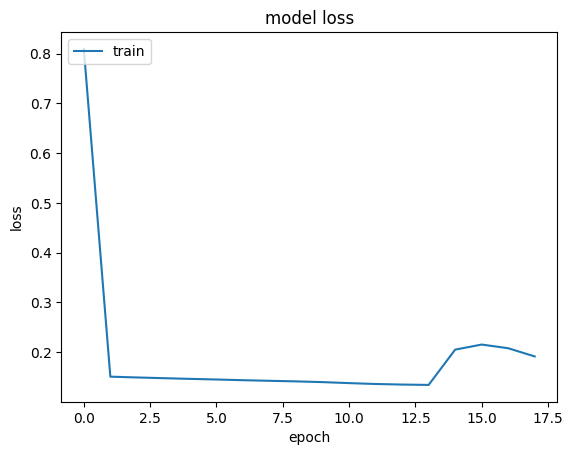

In [3]:
# ---------------------------------
# Model
# ---------------------------------
os.environ['CUDA_VISIBLE_DEVICES'] = '0'
aiModel             = vaeTKAN(config=kanConfig)        

aiModel.compile(optimizer= Adam())
early_stop_loss     = 'loss'
early_stop_callback = EarlyStopping(monitor=early_stop_loss, min_delta = 1e-3, patience=5) 

history = aiModel.fit(
                        x           =   seqData,
                        y           =   seqData,
                        batch_size  =   kanConfig['batchSize'],
                        epochs      =   kanConfig['nEpoch'],
                        shuffle     =   True,
                        callbacks   =   [early_stop_callback],
                        verbose     =   1,
                        )


# ---------------------------------
# Save results
# ---------------------------------
plt.plot(history.history["loss"])
# plt.plot(history.history["val_loss"])
plt.title("model loss")
plt.ylabel("loss")
plt.xlabel("epoch")
plt.legend(["train"],loc ="upper left")

# val_loss = history.history["val_loss"][-1]
# plt.savefig(kanConfig['dir'] + "/" +  "loss" + str(val_loss) + ".png")

In [ ]:
# print("Saving the model ...............")
# aiModel.save('ckpt/VAEConstrains/TKAN_my_model.keras')  # Save as an HDF5 file

# aiModel       = keras.models.load_model('ckpt/VAEConstrains/TKAN_my_model.keras')
# # model.load_weights
# # model       = keras.models.load_model('best_model.h5', custom_objects={'C_constraint': C_constraint})

# # Show the model architecture
# aiModel.summary()
# print("load model successfully")

: 

: 

(4908, 128, 17)


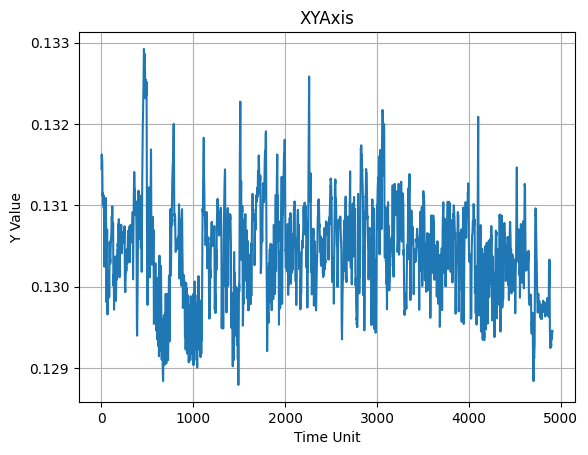

(486, 128, 17)


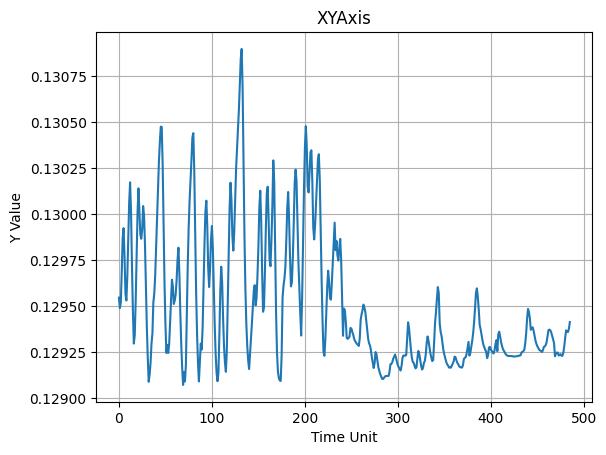

(9561, 128, 17)


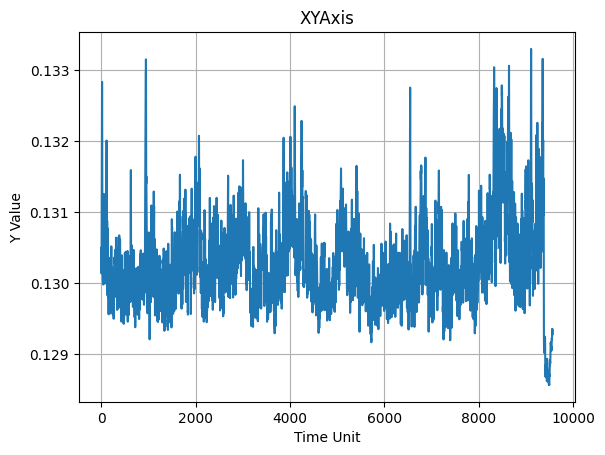

(2937, 128, 17)


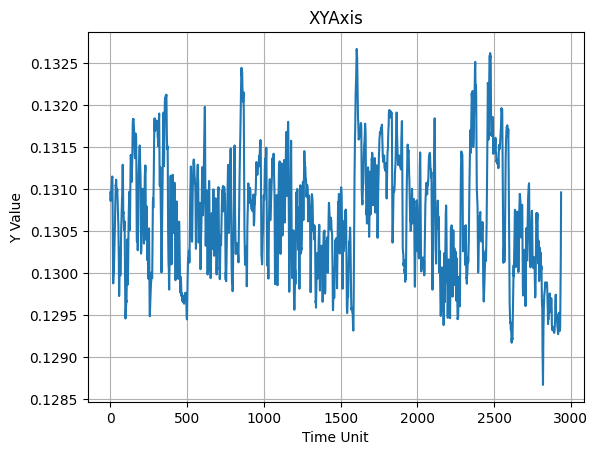

(5694, 128, 17)


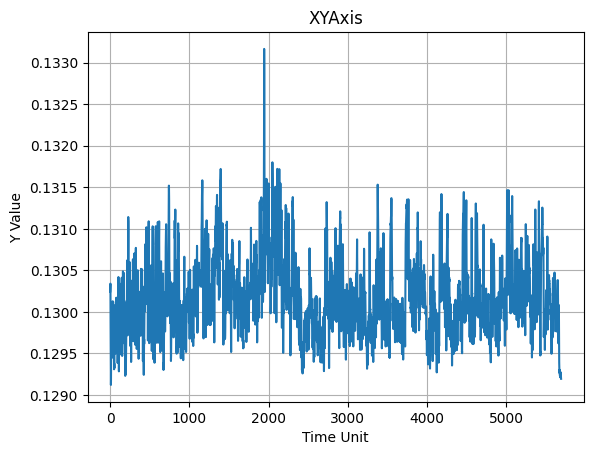

ValueError: need at least one array to stack

In [4]:
plot = MatPlot()

# ======================================
#  PREPROCESS THE DATA
# --------------------------------------
for trajectoryName in trajectory.keys():
    for idx,value in enumerate(trajectory[trajectoryName]):
        singleTraject   = trajectory[trajectoryName][idx][preData.beauEfficiencyCr1 + preData.addEfficiencyCr1]
        seqData,_         = preData.splitAndPadSequencesTensor([singleTraject,singleTraject],seqLength=kanConfig['seqLength'], overlap= kanConfig['overlap']) # Split data into each sequence

        print(seqData.shape)
        zLatent,_     = aiModel(seqData)
        # print(zLatent.shape)
        hi  = tf.reduce_mean(zLatent, axis=1)

        plot.draw1D(hi)